Cel zadania to zbudowanie modelu przewidujacego czy dany samochod osiaga wysoki, czy niski przebieg na galonie paliwa.

In [127]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Podpunkt A  

mpg - mile na galon a wiec wieksza wartosc oznacza nizsze spalanie dla tego mpg wyzsze od mediany to niskie spalanie, a mpg ponizej mediany to wysokie spalanie
0 - wysokie spalanie
1 - niskie spalanie

In [128]:
Auto = pd.read_csv('data/Auto.csv',na_values='?')
Auto = Auto.dropna()
Auto.info()
Auto['mpg01'] = (Auto['mpg']>Auto['mpg'].median()).astype(int) #
display(Auto)

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   year          392 non-null    int64  
 7   origin        392 non-null    int64  
 8   name          392 non-null    str    
dtypes: float64(4), int64(4), str(1)
memory usage: 30.6 KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name,mpg01
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,0
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,0
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,0
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,0
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino,0
...,...,...,...,...,...,...,...,...,...,...
392,27.0,4,140.0,86.0,2790,15.6,82,1,ford mustang gl,1
393,44.0,4,97.0,52.0,2130,24.6,82,2,vw pickup,1
394,32.0,4,135.0,84.0,2295,11.6,82,1,dodge rampage,1
395,28.0,4,120.0,79.0,2625,18.6,82,1,ford ranger,1


# Podpunkt B

Czynniki wplywajce na sapalanie: cylindry,pojemnosc silnika,moc,rocznik silnika,waga. 0 - fioletowy kolor, 1 - zolty kolor

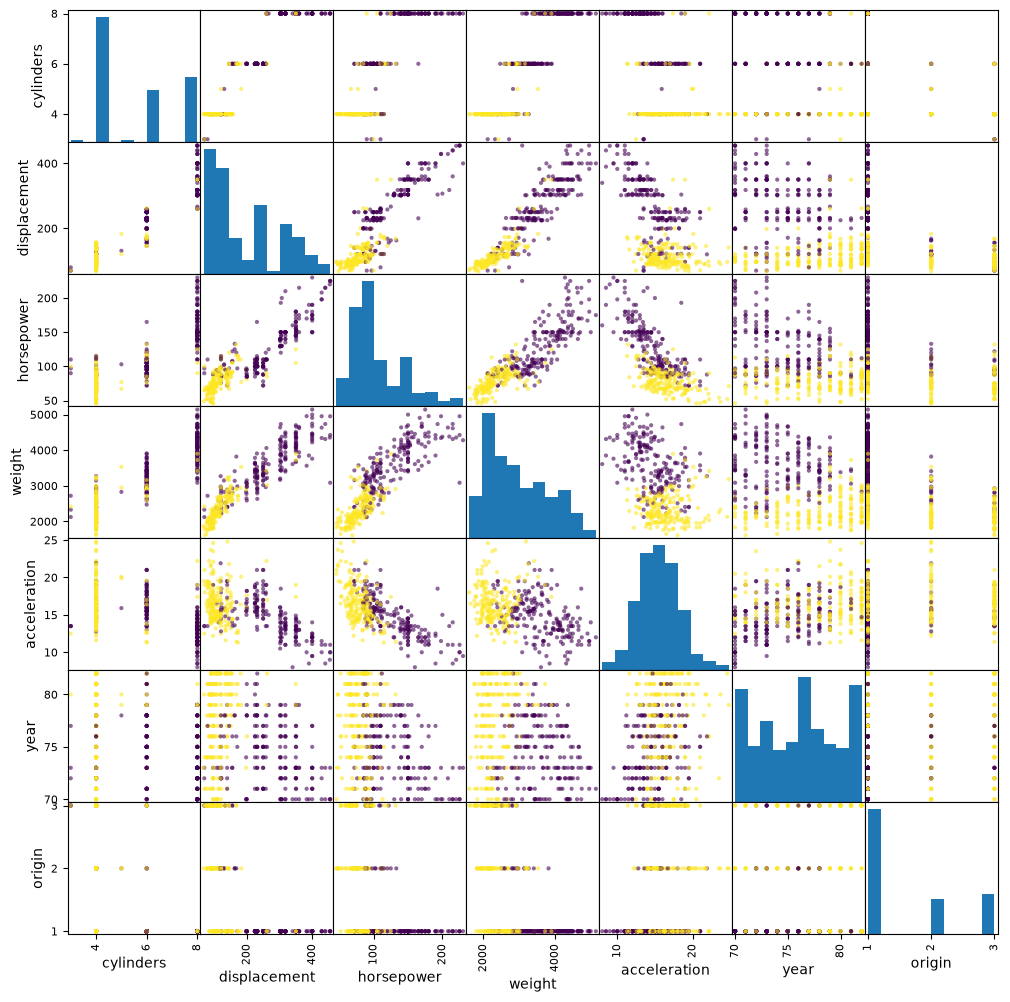

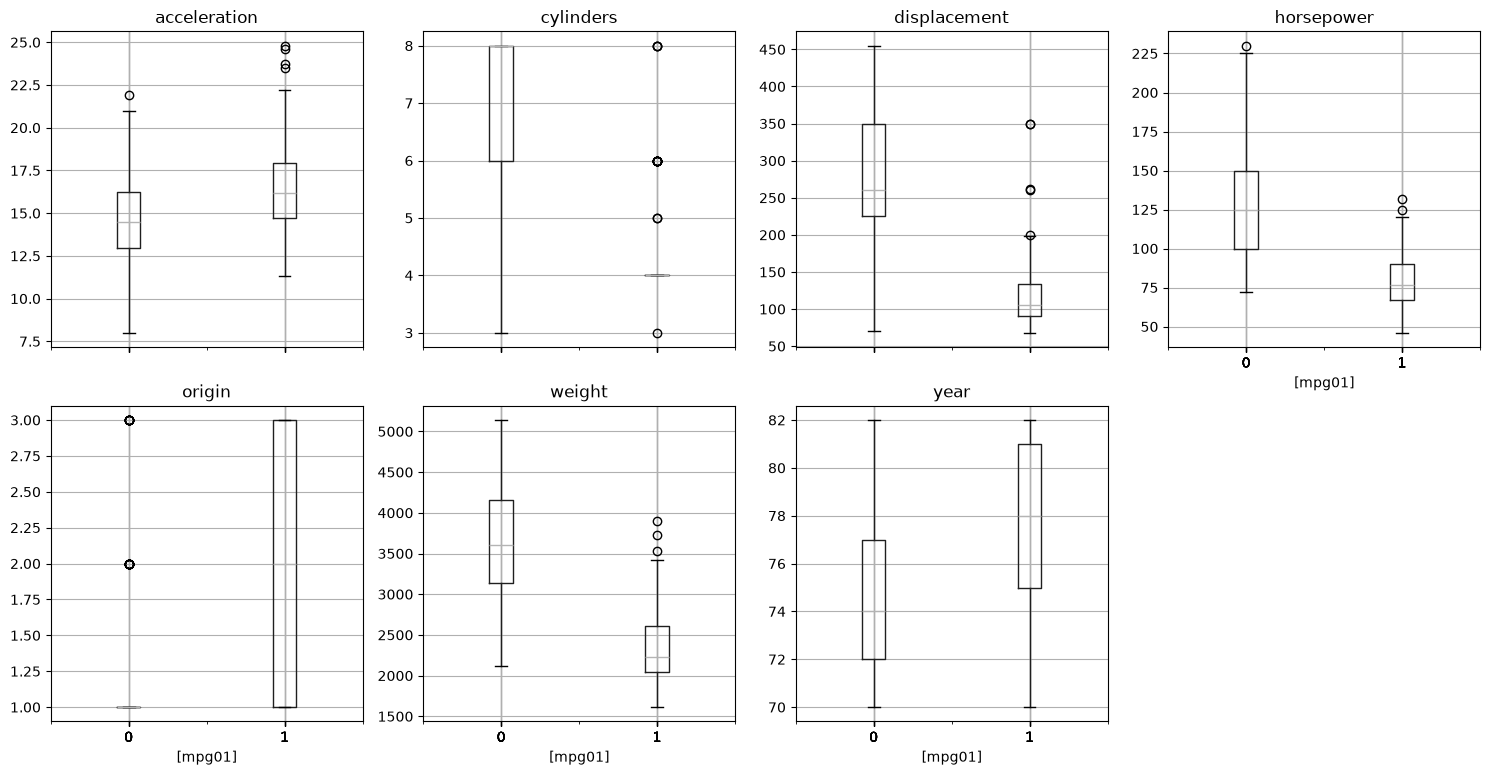

In [129]:
cechy = Auto.drop(columns=['mpg','name','mpg01'])
pd.plotting.scatter_matrix(cechy,c=Auto['mpg01'],diagonal='hist',figsize=(12,12),alpha=0.6)
Auto.drop(columns=['mpg', 'name']).boxplot(by='mpg01', figsize=(15, 8), layout=(2, 4),sharey=False)
plt.suptitle('')
plt.tight_layout()
plt.show()

# Podpunkt C

zbior testowy - 80%, zbior treningowy - 20%

In [130]:
X = Auto[['cylinders', 'displacement', 'horsepower', 'weight', 'year']]
Y = Auto['mpg01']
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)
print(x_train.describe())
print(x_test.describe())


        cylinders  displacement  horsepower       weight        year
count  313.000000    313.000000  313.000000   313.000000  313.000000
mean     5.479233    194.372204  104.821086  2971.670927   75.795527
std      1.711682    106.495604   38.980517   850.115794    3.657147
min      3.000000     68.000000   46.000000  1613.000000   70.000000
25%      4.000000     98.000000   75.000000  2219.000000   73.000000
50%      4.000000    145.000000   95.000000  2745.000000   76.000000
75%      8.000000    302.000000  129.000000  3630.000000   79.000000
max      8.000000    455.000000  230.000000  5140.000000   82.000000
       cylinders  displacement  horsepower       weight       year
count  79.000000     79.000000   79.000000    79.000000  79.000000
mean    5.443038    194.569620  103.075949  3001.012658  76.708861
std     1.692721     97.606048   36.694083   851.580679   3.721565
min     4.000000     79.000000   46.000000  1755.000000  70.000000
25%     4.000000    119.000000   80.000000  

# Podpunkt D,E,F,G,H

### LDA

In [131]:
lda = LinearDiscriminantAnalysis()
lda.fit(x_train, y_train)

y_pred = lda.predict(x_test)

test_error = np.mean(y_pred != y_test)
print("Błąd testowy:", test_error)
print("Dokładność:", 1 - test_error)

Błąd testowy: 0.08860759493670886
Dokładność: 0.9113924050632911


### QDA

In [132]:
qda = QuadraticDiscriminantAnalysis()
qda.fit(x_train, y_train)
y_pred_qda = qda.predict(x_test)
test_error_qda = np.mean(y_pred_qda != y_test)
print("Błąd testowy QDA:",test_error_qda)
print("Dokładność:", 1 - test_error_qda)

Błąd testowy QDA: 0.12658227848101267
Dokładność: 0.8734177215189873


### KNN,LG,naivebayes

In [133]:
clfs = {
    "KNN":Pipeline([('Standard_scaler',StandardScaler()), 
        ('method',KNeighborsClassifier(n_neighbors=7))
    ]),

    "LG":Pipeline([('Standard_scaler',StandardScaler()), 
        ('method',LogisticRegression(max_iter=1000))
    ]),

    "Naive_Bayes":Pipeline([('Standard_scaler',StandardScaler()),
        ('method',GaussianNB())
    ])   
}

In [136]:
predykcje = {}
for (nazwa,clf) in clfs.items():
    clf.fit(x_train,y_train)
    predykcja = clf.predict(x_test)
    predykcje[nazwa] = predykcja
    acc = accuracy_score(y_test, predykcja)
    err = 1 - acc
    print(f"{nazwa}: błąd testowy = {err}, accuracy = {acc}")



KNN: błąd testowy = 0.06329113924050633, accuracy = 0.9367088607594937
LG: błąd testowy = 0.07594936708860756, accuracy = 0.9240506329113924
Naive_Bayes: błąd testowy = 0.11392405063291144, accuracy = 0.8860759493670886


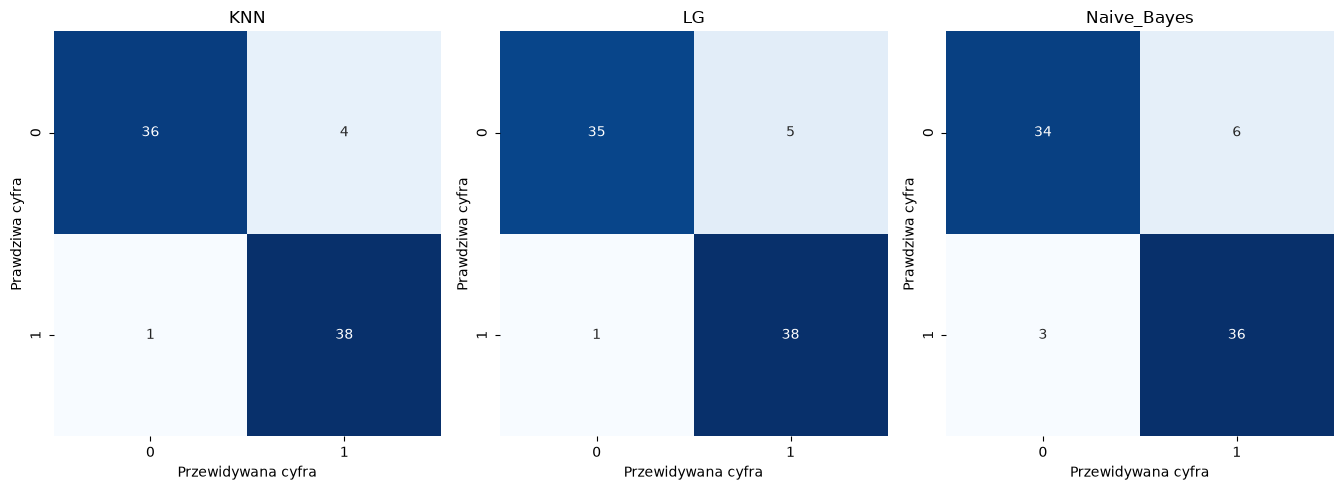

In [137]:
plt.figure(figsize=(18, 5))
for i, (name, pred) in enumerate(predykcje.items(), start=1):
    plt.subplot(1, 4, i)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False) 
    plt.title(f"{name}")
    plt.xlabel("Przewidywana cyfra")
    plt.ylabel("Prawdziwa cyfra") #

plt.tight_layout()
plt.show()